In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import pandas as pd
import seaborn as sns

In [2]:
input_dir = '../../results/02_snakemake_simulate_data/output'

In [3]:
method_list = ['nnSVG', 'Spanve',  'SPARK-X', 'SPARK', 'SpatialDE2',
               'SpatialDE', 'SOMDE', 'MoranI', 'scGCO', 'SpaGCN',
               'SpaGFT', 'GPcounts', 'Sepal', 'BOOST-GP']

In [4]:
def compute_correlation(df, method):
    # reverse the ranking of genes for SPARK, SPARK-X
    if method == 'SPARK-X':
        df['adjustedPval'] = - df['adjustedPval']
    elif method == 'SPARK':
        df['adjusted_pvalue'] = - df['adjusted_pvalue']
    elif method == 'scGCO':
        df['fdr'] = - df['fdr']
    elif method == 'SpaGCN':
        df['pvals_adj'] = - df['pvals_adj']
        
    if method == 'GPcounts':
        df['log_likelihood_ratio'] = df['log_likelihood_ratio'].fillna(0)
        
    if method == 'BOOST-GP':
        df['PPI'] = df['PPI'].fillna(0)
        
    groupby = df.groupby('gene', observed=True)
    
    if method == 'nnSVG':
        corr = groupby.apply(lambda x: x['LR_stat'].corr(x['spatial_var'], method='kendall'))
    elif method == 'Spanve':
        corr = groupby.apply(lambda x: x['ent'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SPARK-X':
        corr = groupby.apply(lambda x: x['adjustedPval'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SPARK':
        corr = groupby.apply(lambda x: x['adjusted_pvalue'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SpatialDE2':
        corr = groupby.apply(lambda x: x['FSV'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SpatialDE':
        corr = groupby.apply(lambda x: x['FSV'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SOMDE':
        corr = groupby.apply(lambda x: x['FSV'].corr(x['spatial_var'], method='kendall'))        
    elif method == 'MoranI':
        corr = groupby.apply(lambda x: x['I'].corr(x['spatial_var'], method='kendall'))
    elif method == 'scGCO':
        corr = groupby.apply(lambda x: x['fdr'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SpaGCN':
        corr = groupby.apply(lambda x: x['pvals_adj'].corr(x['spatial_var'], method='kendall'))
    elif method == 'SpaGFT':
        corr = groupby.apply(lambda x: x['gft_score'].corr(x['spatial_var'], method='kendall'))
    elif method == 'GPcounts':
        corr = groupby.apply(lambda x: x['log_likelihood_ratio'].corr(x['spatial_var'], method='kendall'))
    elif method == 'Sepal':
        corr = groupby.apply(lambda x: x['sepal_score'].corr(x['spatial_var'], method='kendall'))
    elif method == 'BOOST-GP':
        corr = groupby.apply(lambda x: x['PPI'].corr(x['spatial_var'], method='kendall'))
    else:
        print(f'unknown method: {method}')
        
    return corr.mean()

In [5]:
def get_correlations(dataset_list):
    corrs, datasets, methods = [], [], []
    for dataset in dataset_list:
        for method in method_list:
            input_filename = f'{input_dir}/{method}/{dataset}.csv'

            if os.path.exists(input_filename):
                df = pd.read_csv(input_filename)
                corr = compute_correlation(df, method)
            else:
                print(f'cannot find {input_filename}!')
                continue
            
            corrs.append(corr)
            datasets.append(dataset)
            methods.append(method)
        
    df = pd.DataFrame(data={'correlation': corrs, 'dataset': datasets, 'method': methods})
    df['correlation'] = df['correlation'].fillna(0)
    
    return df

cannot find ../../results/02_snakemake_simulate_data/output/GPcounts/05_10x_Visium_Mouse_Embryo.csv!


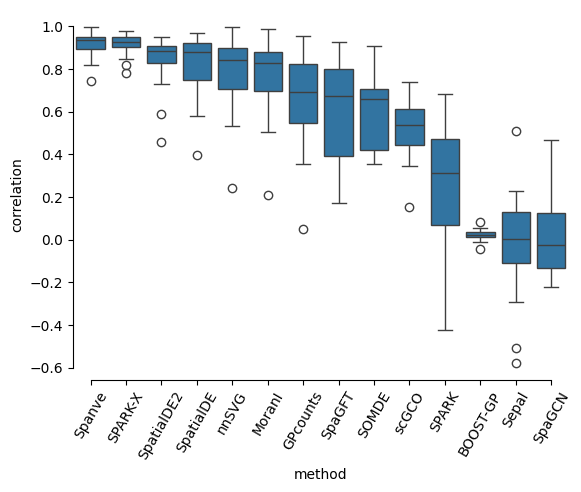

In [6]:
dataset_list = ['01_10x_Visium_mouse_brain',
                '02_10x_Visium_Human_Heart_MI',
                '03_10x_Visium_Human_Colorectal_Cancer',
                '04_10x_Visium_Human_Heart',
                '05_10x_Visium_Mouse_Embryo',
                '06_10x_Visium_Mouse_Olfactory_Bulb',
                '07_10x_Visium_Human_Breast_Cancer',
                '08_10x_Visium_Human_Lymph_Node',
                '09_10x_Visium_Human_Prostate',
                '10_10x_Visium_Human_Prostate_Cancer',
                '11_10x_Visium_Human_Cerebellum',
                '12_10x_Visium_Mouse_Kidney',
                '13_10x_Visium_Human_Lung_Cancer',
                '14_10x_Visium_Human_Brain_Cancer',
                '15_10x_Visium_Human_Kidney',
                '16_10x_Visium_Human_Intestine_Cancer',
                '17_10x_Visium_Human_Skin_Melanoma',
                '18_10x_Visium_Human_Cervical_Cancer',
                '19_10x_Visium_Human_Breast_Cancer',
                '20_10x_Visium_Human_Heart_MI',
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/10x_Visium_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/SpaGCN/21_slide_seqv2_Mouse_Olfactory_Bulb.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SOMDE/22_slide_seqv2_Mouse_Cortex.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SpaGCN/22_slide_seqv2_Mouse_Cortex.csv!
cannot find ../../results/02_snakemake_simulate_data/output/GPcounts/22_slide_seqv2_Mouse_Cortex.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SpaGCN/23_slide_seqv2_Mouse_Cerebellum.csv!
cannot find ../../results/02_snakemake_simulate_data/output/GPcounts/23_slide_seqv2_Mouse_Cerebellum.csv!
cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/23_slide_seqv2_Mouse_Cerebellum.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SpaGCN/24_slide_seqv2_Mouse_Hippocampus.csv!
cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/24_slide_seqv2_Mouse_Hippocampus.csv!
cannot find ../../results/02_snakemake_simulate_data/output/Spa

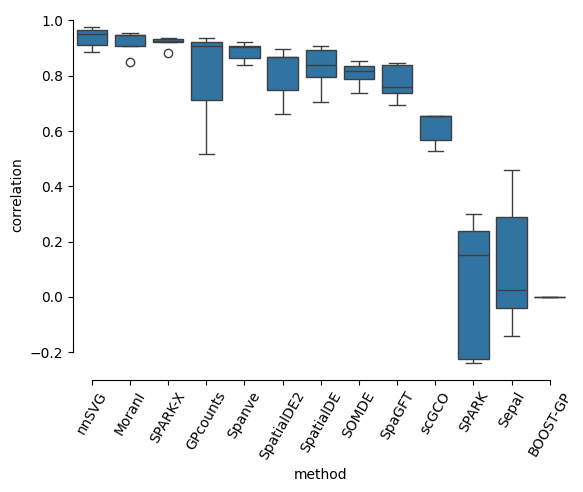

In [7]:
dataset_list = ['21_slide_seqv2_Mouse_Olfactory_Bulb',
                '22_slide_seqv2_Mouse_Cortex',
                '23_slide_seqv2_Mouse_Cerebellum',
                '24_slide_seqv2_Mouse_Hippocampus',
                '25_slide_seqv2_Mouse_SomatosensoryCortex'
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/slide_seqv2_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/SpaGCN/28_DBiT_seq_E10_whole.csv!


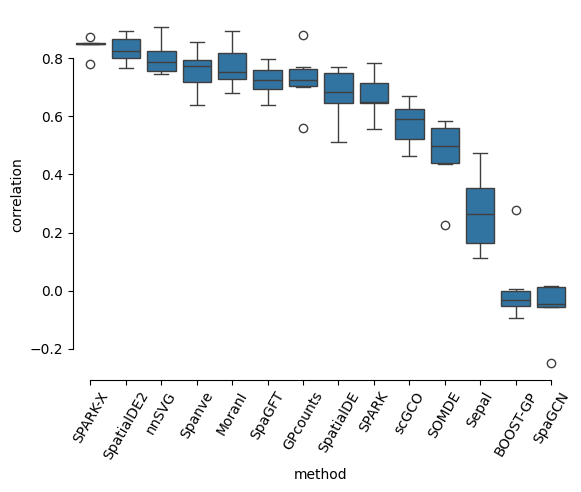

In [8]:
dataset_list = ['26_DBiT_seq_E10_brain',
                '27_DBiT_seq_E10_eye',
                '28_DBiT_seq_E10_whole',
                '29_DBiT_seq_E11_lower_body',
                '30_DBiT_seq_E11_FL_1L',
                '31_DBiT_seq_E11_FL_2L'
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/DBiT_seq_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/32_10x_Xenium_Human_Colon_Cancer.csv!


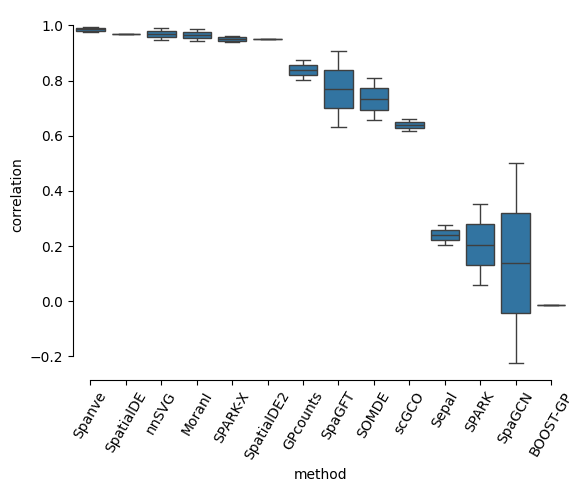

In [9]:
dataset_list = ['32_10x_Xenium_Human_Colon_Cancer',
                '33_10x_Xenium_Mouse_Brain'
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/10x_Xenium_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/35_MERFISH_Human_cortex.csv!
cannot find ../../results/02_snakemake_simulate_data/output/nnSVG/38_MERFISH_Mouse_cortex.csv!
cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/38_MERFISH_Mouse_cortex.csv!


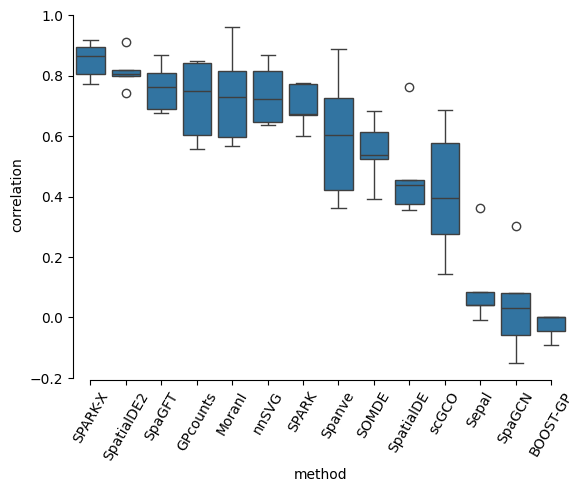

In [10]:
dataset_list = ['34_MERFISH_Human_cortex',
                '35_MERFISH_Human_cortex',
                '36_MERFISH_Human_cortex',
                '37_MERFISH_Human_cortex',
                '38_MERFISH_Mouse_cortex',
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/MERFISH_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/SpaGCN/39_seqFISH_Mouse_Organogenesis.csv!
cannot find ../../results/02_snakemake_simulate_data/output/GPcounts/39_seqFISH_Mouse_Organogenesis.csv!
cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/39_seqFISH_Mouse_Organogenesis.csv!


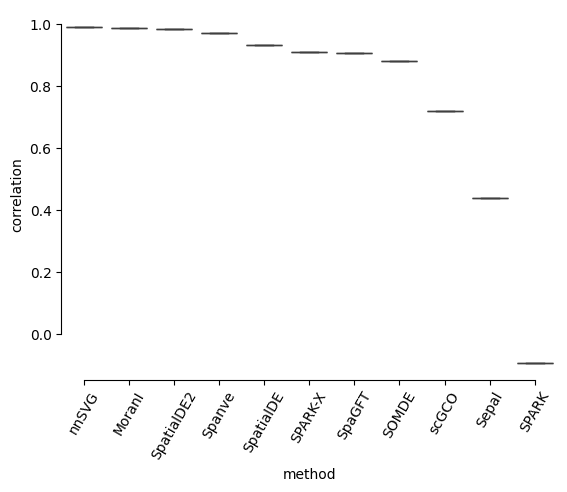

In [11]:
dataset_list = ['39_seqFISH_Mouse_Organogenesis',
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/seqFISH_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/42_slide_tag_human_skin_melanoma.csv!
cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/43_slide_tag_human_tonsil.csv!


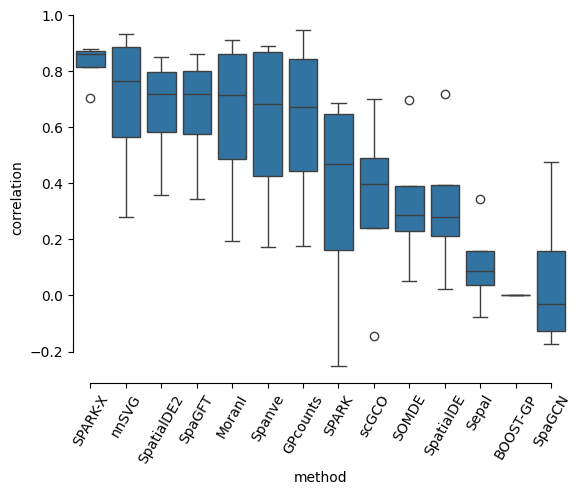

In [12]:
dataset_list = ['40_slide_tag_mouse_embryo',
                '41_slide_tag_human_cortex',
                '42_slide_tag_human_skin_melanoma',
                '43_slide_tag_human_tonsil',
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/slide_tag_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/SOMDE/44_stereo_seq_Drosophila_embryo_E7.csv!
cannot find ../../results/02_snakemake_simulate_data/output/Sepal/44_stereo_seq_Drosophila_embryo_E7.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SOMDE/45_stereo_seq_Drosophila_embryo_E9.1.csv!
cannot find ../../results/02_snakemake_simulate_data/output/Sepal/45_stereo_seq_Drosophila_embryo_E9.1.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SOMDE/46_stereo_seq_Drosophila_embryo_E6.3.csv!
cannot find ../../results/02_snakemake_simulate_data/output/Sepal/46_stereo_seq_Drosophila_embryo_E6.3.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SOMDE/47_stereo_seq_Drosophila_embryo_E10.5.csv!
cannot find ../../results/02_snakemake_simulate_data/output/Sepal/47_stereo_seq_Drosophila_embryo_E10.5.csv!
cannot find ../../results/02_snakemake_simulate_data/output/SOMDE/48_stereo_seq_Drosophila_embryo_E5.6.csv!
cannot find ../../results/02_s

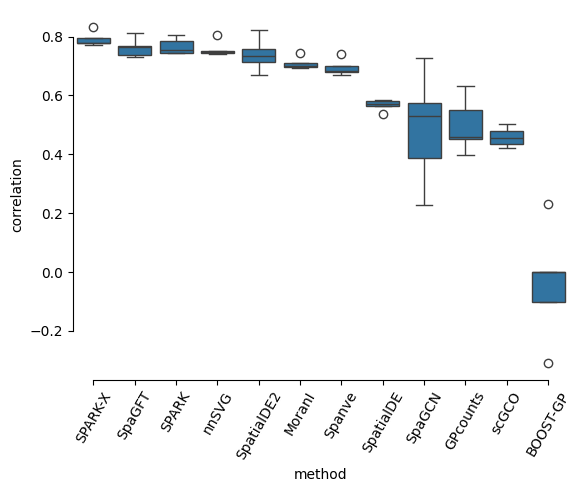

In [13]:
dataset_list = ['44_stereo_seq_Drosophila_embryo_E7',
                '45_stereo_seq_Drosophila_embryo_E9.1',
                '46_stereo_seq_Drosophila_embryo_E6.3',
                '47_stereo_seq_Drosophila_embryo_E10.5',
                '48_stereo_seq_Drosophila_embryo_E5.6',
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/stereo_seq_correlation.csv')

cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/49_STARmap_Wang2018_2D_zstep10_0.csv!
cannot find ../../results/02_snakemake_simulate_data/output/BOOST-GP/50_STARmap_Wang2018_2D_zstep15_0.csv!


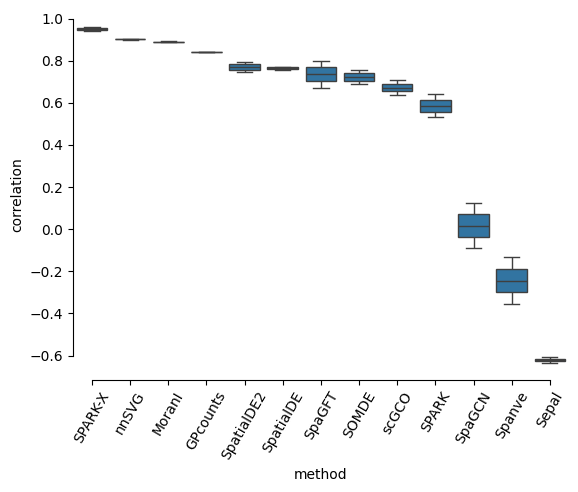

In [14]:
dataset_list = ['49_STARmap_Wang2018_2D_zstep10_0',
                '50_STARmap_Wang2018_2D_zstep15_0'
               ]

df = get_correlations(dataset_list)

ranks = df.groupby("method")["correlation"].median().fillna(0).sort_values()[::-1].index
ax = sns.boxplot(df, x='method', y='correlation', order = ranks)
ax.tick_params(axis='x', rotation=60)
sns.despine(trim=True)

df.to_csv('../../results/03_eval_simulate_data/STARmap_correlation.csv')